# Skill selection

**Recipe 28** · Level 3 (Intermediate) · Decision type: `Score`

Score retrieved skill descriptions for relevance to a task so Python can select a suitable skill or request clarification.

Sources:

- S02: [TypeSafe AI: Primitives (Questions)](https://docs.typesafe.ai/primitives)
- S03: [TypeSafe AI: Confidence](https://docs.typesafe.ai/confidence)
- S04: [TypeSafe AI: How to build with TypeSafe](https://docs.typesafe.ai/concepts/how-to-build-with-system-one)
- S06: [TypeSafe AI: Cookbooks](https://docs.typesafe.ai/cookbooks)

## What you will build

An agent is choosing which of several skills should carry out a task. Python keeps a small, fixed catalog of skills and, for each task, retrieves a short list of candidates by a simple lexical overlap with their own descriptions. Jev then scores exactly one thing, once per candidate: how well that one skill's own description shows it can carry out the task, on a four-level rubric. Python never asks Jev to compare skills against each other; it ranks the candidates itself from their scores and decides, with three separate checks, whether to act automatically: the top skill's own answer has to be confident enough to trust, its score has to clear a fixed business cutoff, and it has to clearly beat the runner-up by a margin chosen from `validation`. When any check fails -- the top judgment is too unsure, the best candidate still does not really fit, or two candidates are close enough to be a guess -- the task goes to a person to clarify instead of picking one. By the end you will have seen one relevance `Score` up close for three different tasks (a clear winner, two skills that are genuinely both plausible, and a task no retrieved skill really fits), the rule that composes several such scores into one task-level decision, and an evaluation at both levels: how good each individual relevance score is against its own gold level, and how often the composed decision names the right skill versus asks for help.

## Setup and run mode

The notebook runs from its own folder and needs only the standard library and `jev_cookbook`. `get_backend(fixtures=...)` replays stored answers offline; setting `JEV_COOKBOOK_LIVE=1` (see the README) swaps in live calls and changes nothing else. The header states which mode ran, and every number below carries that mode with it.

In [1]:
from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import (
    evaluate_outcomes,
    exact_agreement,
    mean_absolute_error,
    score_level,
    selective_curve,
)
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path, select_split
from jev_cookbook.style import apply_style, plot_risk_coverage, run_header, show_answer

apply_style()
helpers = load_helpers()  # this recipe's helpers.py, loaded by path
examples = load_inputs()
labels = load_labels()
backend = get_backend(fixtures=responses_path())
# N for the header is the number of (task, skill) requests the per-question metrics
# below cover: validation and test. The three demo tasks are shown up close but never
# scored.
scored = [e for e in examples if e.split not in ("train", "demo")]

offline = backend.mode in ("synthetic", "scripted")
check = " (a pipeline check, not a Jev result)" if offline else ""
# CONTRIBUTING.md section 2: "a number from the validation split is a selection step,
# not a result." This label does not depend on the run mode, unlike `check` above.
selection = " (a selection step, not a reported result)"

# Every one of the 39 (task, skill) requests in fixtures/ needs at most one request:
# this cache makes sure a request shown individually up close and later reused in an
# evaluation loop is decided once, so the whole notebook makes exactly 39 requests in
# live mode, never more (see "Switch to live" in the README for how that count is
# checked).
answered = {}


def decide(example):
    if example.id not in answered:
        answered[example.id] = backend.decide(helpers.build_state(example.fields), questions)[
            "relevance"
        ]
    return answered[example.id]


run_header(28, "Skill selection", backend=backend, n_examples=len(scored))

Recipe 28: Skill selection
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 30 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

The state is everything Jev sees for one (task, skill) pair, and Python builds it. Each example in `fixtures/inputs.jsonl` carries `fields`: a task id, the task's own text, a skill id, and that one skill's own catalog description. `build_state` passes on the task text and the skill's description only -- never the other candidate skills, and never either identifier, so a result always traces back to its task and skill without either one ever passing through the model.

In [2]:
import json

demo = {e.id: e for e in examples if e.split == "demo"}
example = demo["d01-expense_report"]
print("Python has:")
print(json.dumps(example.fields, indent=2))
state = helpers.build_state(example.fields)
print("Jev sees:")
print(json.dumps(state, indent=2))

Python has:
{
  "task_id": "d01",
  "task": "Submit my taxi and hotel receipts from last week's client visit for reimbursement.",
  "skill_id": "expense_report",
  "skill": "Files an expense report: submits a receipt for reimbursement and reports the status of a submitted claim."
}
Jev sees:
{
  "task": "Submit my taxi and hotel receipts from last week's client visit for reimbursement.",
  "skill": "Files an expense report: submits a receipt for reimbursement and reports the status of a submitted claim."
}


## The questions

There is one question, `relevance`, and it asks one thing: how well does this one skill's own description show it can carry out this task? A `Score` fits because suitability is a matter of degree, not a single named option, and it lets the evaluation below ask both how good one judgment is against its own gold level and how the composed decision does across several of them. Python builds the four-level rubric from `helpers.SUITABILITY_LEVELS`, lowest level first, and every level is written to stand on its own (TypeSafe's guidance: a `Score` level is judged independently, never "worse than the level above"). The same question is asked once per retrieved candidate skill, never once per task with several skills compared against each other: Jev only ever sees one skill's description at a time, so the comparison between candidates is entirely Python's.

In [3]:
questions = helpers.build_questions()
relevance = questions["relevance"]
print(relevance.instructions)
for level, description in enumerate(relevance.criteria):
    print(f"  {level}  {description}")

How well does this skill's own description show that it can carry out this task? Judge only what this skill's description itself states, not what any other skill might do.
  0  The skill's description names a different kind of action, or a different kind of information, than what the task asks for. Nothing the description states would let this skill carry out the task.
  1  The skill's description names the same general area of work as the task, but it does not state that it performs the specific action, on the specific kind of thing, that the task asks for.
  2  The skill's description states that it performs the specific action the task asks for. The description may also cover other actions the task does not need, or may not name every secondary detail the task mentions.
  3  The skill's description states that it performs the specific action the task asks for, and also names, by itself, the particular detail (the kind of item, the system, or the scope) that the task asks about.


## One answer up close

Before any aggregate, look at the typed answers for three tasks that show the three shapes this recipe's rule can land on. A `Score` answer holds the most probable level (its distribution's peak), a probability for every level, an expected `score` that can fall between two levels, and a `confidence` summarizing how peaked the distribution is -- the probability-weighted distance from the most likely level, divided by the same quantity for an even spread, from [TypeSafe's confidence page](https://docs.typesafe.ai/confidence) (S03). Each task below retrieved three candidate skills; the three cells show every candidate's answer for that task, in the order Python retrieved them.

In [4]:
demo_by_task = helpers.group_by_task_id([e for e in examples if e.split == "demo"])

select_examples = demo_by_task["d01"]
print(select_examples[0].fields["task"])
for example in select_examples:
    skill_id = example.fields["skill_id"]
    print(f"\n{skill_id}: {helpers.SKILL_CATALOG[skill_id]}")
    show_answer(decide(example))

Submit my taxi and hotel receipts from last week's client visit for reimbursement.

travel_booking: Books travel for a trip: reserves a flight, a hotel room, or a rental car and confirms the itinerary.
Score: 0.44 (confidence 0.56)
  0 The skill's description names a different kind of action, or a different kind of information,
    than what the task asks for. Nothing the description states would let this skill carry out the
    task.  0.72  ##############
  1 The skill's description names the same general area of work as the task, but it does not state
    that it performs the specific action, on the specific kind of thing, that the task asks for.  0.16  ###
  2 The skill's description states that it performs the specific action the task asks for. The
    description may also cover other actions the task does not need, or may not name every secondary
    detail the task mentions.  0.08  ##
  3 The skill's description states that it performs the specific action the task asks for, and a

In [5]:
ambiguous_examples = demo_by_task["d02"]
print(ambiguous_examples[0].fields["task"])
for example in ambiguous_examples:
    skill_id = example.fields["skill_id"]
    print(f"\n{skill_id}: {helpers.SKILL_CATALOG[skill_id]}")
    show_answer(decide(example))

Handle the calendar schedule and travel logistics for next week's trip to the Seattle offsite.

travel_booking: Books travel for a trip: reserves a flight, a hotel room, or a rental car and confirms the itinerary.
Score: 2.38 (confidence 0.38)
  0 The skill's description names a different kind of action, or a different kind of information,
    than what the task asks for. Nothing the description states would let this skill carry out the
    task.  0.04  #
  1 The skill's description names the same general area of work as the task, but it does not state
    that it performs the specific action, on the specific kind of thing, that the task asks for.  0.09  ##
  2 The skill's description states that it performs the specific action the task asks for. The
    description may also cover other actions the task does not need, or may not name every secondary
    detail the task mentions.  0.32  ######
  3 The skill's description states that it performs the specific action the task asks for, and

In [6]:
cutoff_examples = demo_by_task["d03"]
print(cutoff_examples[0].fields["task"])
for example in cutoff_examples:
    skill_id = example.fields["skill_id"]
    print(f"\n{skill_id}: {helpers.SKILL_CATALOG[skill_id]}")
    show_answer(decide(example))

Set up a recurring reminder to track my conference travel expenses.

travel_booking: Books travel for a trip: reserves a flight, a hotel room, or a rental car and confirms the itinerary.
Score: 1.17 (confidence 0.65)
  0 The skill's description names a different kind of action, or a different kind of information,
    than what the task asks for. Nothing the description states would let this skill carry out the
    task.  0.09  ##
  1 The skill's description names the same general area of work as the task, but it does not state
    that it performs the specific action, on the specific kind of thing, that the task asks for.  0.71  ##############
  2 The skill's description states that it performs the specific action the task asks for. The
    description may also cover other actions the task does not need, or may not name every secondary
    detail the task mentions.  0.14  ###
  3 The skill's description states that it performs the specific action the task asks for, and also
    names, 

## Python's part

Jev supplies one relevance score per candidate skill; the rule that turns several of those into one task-level decision is code, in `helpers.select_skill`. It ranks the task's candidates by their expected `score` (ties broken by retrieval order, never an incidental later sort), then checks three things, in order, any one of which can send the task to [review](../../docs/glossary.md#review) on its own:

- **The [confidence gate](../../docs/glossary.md#confidence-gate)**: the top skill's own answer [confidence](../../docs/glossary.md#confidence) -- how peaked its probability distribution over the four levels is, nothing to do with the other candidates -- has to clear a gate chosen on `validation` and frozen below. A spread-out distribution is not solid ground for acting on, whatever level it happens to peak at.
- **The business cutoff** (`helpers.BUSINESS_CUTOFF`, fixed, never chosen from data): the top skill's own most probable level must be `suitable` or better. A skill whose description does not even state that it can do the task is never selected, however far ahead of the runner-up it scored.
- **The margin**: the gap between the top skill's expected score and the runner-up's, normalized to 0-1, has to clear a margin threshold chosen on `validation` and frozen below. This is the check for the hard case the use case names: two skills whose descriptions both plausibly fit the task, scored close together. Picking either one without asking is a guess Python should not make automatically.

A task that fails any check is held for a person to clarify which skill is meant -- a clarification is a [review](../../docs/glossary.md#review) outcome, not an action: nothing is sent, assigned, or run, and the task simply waits for a person to say which skill to use. Both the gate and the threshold are chosen the same way: `helpers.select_confidence_gate` and `helpers.select_margin_threshold` each pick the highest-accuracy cut-off that still answers at least half of their own pool (`helpers.CONFIDENCE_MIN_COVERAGE` and `helpers.MARGIN_MIN_COVERAGE`), rather than demanding perfect accuracy on `validation` outright, which would be true by construction and tell a reader nothing. The two pools differ on purpose: every validation task's top judgment sets the bar for the confidence gate, since it is checked first and nothing has ruled a task out yet; only the tasks whose top skill already clears the business cutoff set the bar for the margin, the same reasoning the template uses for its own confidence gate -- a task the cutoff alone would reject can never reach the margin check to begin with.

In [7]:
val_examples = select_split(examples, "validation")
val_groups = helpers.group_by_task_id(val_examples)
val_judgments_by_task = {
    task_id: [
        helpers.Judgment(
            e.fields["skill_id"], score_level(decide(e)), decide(e).score, decide(e).confidence
        )
        for e in exs
    ]
    for task_id, exs in val_groups.items()
}
val_gold_best_by_task = {
    task_id: helpers.gold_best_skills({e.fields["skill_id"]: labels[e.id] for e in exs})
    for task_id, exs in val_groups.items()
}

conf_correct, conf_pool = helpers.pool_for_confidence_selection(
    val_judgments_by_task, val_gold_best_by_task
)
confidence_gate = helpers.select_confidence_gate(conf_correct, conf_pool)
print(f"chosen confidence gate, frozen from here on: {confidence_gate:.4f}{selection}{check}")

pool_correct, pool_margin = helpers.pool_for_margin_selection(
    val_judgments_by_task, val_gold_best_by_task
)
print(
    f"validation tasks whose top skill clears the business cutoff: "
    f"{len(pool_correct)} of {len(val_groups)}{selection}{check}"
)
margin_threshold = helpers.select_margin_threshold(pool_correct, pool_margin)
print(f"chosen margin threshold, frozen from here on: {margin_threshold:.4f}{selection}{check}")

for task_id in ("d01", "d02", "d03"):
    task_examples = demo_by_task[task_id]
    judgments = [
        helpers.Judgment(
            e.fields["skill_id"], score_level(decide(e)), decide(e).score, decide(e).confidence
        )
        for e in task_examples
    ]
    result = helpers.select_skill(task_id, judgments, confidence_gate, margin_threshold)
    print(
        f"{task_id}: top {result.skill_id} (level {result.level}, margin "
        f"{result.margin:.4f}) -> {result.outcome} ({result.reason})"
    )

chosen confidence gate, frozen from here on: 0.3600 (a selection step, not a reported result) (a pipeline check, not a Jev result)
validation tasks whose top skill clears the business cutoff: 4 of 5 (a selection step, not a reported result) (a pipeline check, not a Jev result)
chosen margin threshold, frozen from here on: 0.7800 (a selection step, not a reported result) (a pipeline check, not a Jev result)
d01: top expense_report (level 3, margin 0.7800) -> select (clearly the best-fitting skill)
d02: top travel_booking (level 3, margin 0.0400) -> review (the margin between the top two skills is below the threshold)
d03: top expense_report (level 1, margin 0.0033) -> review (the top skill's modal level is below the business cutoff)


## Evaluation

The confidence gate and the margin threshold were both chosen and frozen above, on `validation`. This section reports two different things, at two different levels, and keeps them separate: **per question**, how well each individual relevance score agrees with its own [gold label](../../docs/glossary.md#gold-label) -- here, the suitability level a person would have given that one (task, skill) pair, from `fixtures/labels.jsonl`, never shown to Jev; and **per task**, how often `helpers.select_skill`'s composed decision, built from every one of a task's candidate scores, names a correct skill versus sends the task to review. The composed decision is never reimplemented here: every number below comes from calling `helpers.select_skill` and `helpers.outcome_accounting` on the actual answers, the same functions `tests/test_helpers.py` tests directly. `test` is used once, to report; `validation` numbers are a selection step, labelled as such even where they are not literally what chose a threshold.

In [8]:
val_gold = [labels[e.id] for e in val_examples]
val_answers = [decide(e) for e in val_examples]
print(f"validation, {len(val_examples)} (task, skill) requests{selection}{check}")
print(f"  exact-level agreement: {exact_agreement(val_gold, val_answers):.4f}{selection}{check}")
print(
    f"  mean absolute error: {mean_absolute_error(val_gold, val_answers):.4f} levels"
    f"{selection}{check}"
)

test_examples = select_split(examples, "test")
test_gold = [labels[e.id] for e in test_examples]
test_answers = [decide(e) for e in test_examples]
print(f"\ntest, {len(test_examples)} (task, skill) requests{check}")
print(f"  exact-level agreement: {exact_agreement(test_gold, test_answers):.4f}{check}")
print(f"  mean absolute error: {mean_absolute_error(test_gold, test_answers):.4f} levels{check}")

validation, 15 (task, skill) requests (a selection step, not a reported result) (a pipeline check, not a Jev result)
  exact-level agreement: 0.8667 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  mean absolute error: 0.5360 levels (a selection step, not a reported result) (a pipeline check, not a Jev result)

test, 15 (task, skill) requests (a pipeline check, not a Jev result)
  exact-level agreement: 0.8667 (a pipeline check, not a Jev result)
  mean absolute error: 0.6180 levels (a pipeline check, not a Jev result)


In [9]:
print("test (task, skill) requests the per-question score got wrong:")
for example, answer, gold in zip(test_examples, test_answers, test_gold, strict=True):
    level = score_level(answer)
    if level != gold:
        print(
            f"  {example.id}: gold level {gold}, modal level {level} "
            f"(confidence {answer.confidence:.2f})"
        )

test (task, skill) requests the per-question score got wrong:
  t05-doc_search: gold level 3, modal level 0 (confidence 0.56)
  t05-expense_report: gold level 1, modal level 3 (confidence 0.78)


In [10]:
def task_selections(split_examples, confidence_gate, margin_threshold):
    groups = helpers.group_by_task_id(split_examples)
    selections = []
    gold_best_by_task = {}
    for task_id, exs in sorted(groups.items()):
        judgments = [
            helpers.Judgment(
                e.fields["skill_id"],
                score_level(decide(e)),
                decide(e).score,
                decide(e).confidence,
            )
            for e in exs
        ]
        gold_best_by_task[task_id] = helpers.gold_best_skills(
            {e.fields["skill_id"]: labels[e.id] for e in exs}
        )
        selections.append(
            helpers.select_skill(task_id, judgments, confidence_gate, margin_threshold)
        )
    return selections, gold_best_by_task


val_selections, val_gold_best = task_selections(val_examples, confidence_gate, margin_threshold)
print(f"validation, {len(val_selections)} tasks{selection}{check}")
for s in val_selections:
    print(
        f"  {s.task_id}: {s.skill_id} (level {s.level}, margin {s.margin:.4f}) "
        f"-> {s.outcome} ({s.reason}){selection}{check}"
    )
val_accepted, val_correct = helpers.outcome_accounting(val_selections, val_gold_best)
val_result = evaluate_outcomes(val_accepted, val_correct)
print(f"selected automatically: {val_result.n_answered} of {val_result.n_total}{selection}{check}")
print(f"top-1 accuracy among those selected: {val_result.accuracy:.4f}{selection}{check}")
print(f"clarification rate: {1 - val_result.coverage:.4f}{selection}{check}")

validation, 5 tasks (a selection step, not a reported result) (a pipeline check, not a Jev result)
  v01: travel_booking (level 3, margin 0.7800) -> select (clearly the best-fitting skill) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  v02: code_review_summary (level 3, margin 0.7800) -> select (clearly the best-fitting skill) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  v03: expense_report (level 1, margin 0.0033) -> review (the top skill's modal level is below the business cutoff) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  v04: calendar_scheduling (level 3, margin 0.0233) -> review (the margin between the top two skills is below the threshold) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  v05: travel_booking (level 3, margin 0.3300) -> review (confidence below the threshold) (a selection step, not a reported result) (a pipeline check, not a Je

In [11]:
test_selections, test_gold_best = task_selections(test_examples, confidence_gate, margin_threshold)
print(
    f"\ntest, {len(test_selections)} tasks, confidence gate {confidence_gate:.4f} and "
    f"margin threshold {margin_threshold:.4f} frozen{check}"
)
for s in test_selections:
    print(
        f"  {s.task_id}: {s.skill_id} (level {s.level}, margin {s.margin:.4f}) "
        f"-> {s.outcome} ({s.reason}){check}"
    )
test_accepted, test_correct = helpers.outcome_accounting(test_selections, test_gold_best)
test_result = evaluate_outcomes(test_accepted, test_correct)
print(f"selected automatically: {test_result.n_answered} of {test_result.n_total}{check}")
print(f"top-1 accuracy among those selected: {test_result.accuracy:.4f}{check}")
print(f"risk among those selected: {test_result.risk:.4f}{check}")
print(f"clarification rate: {1 - test_result.coverage:.4f}{check}")


test, 5 tasks, confidence gate 0.3600 and margin threshold 0.7800 frozen (a pipeline check, not a Jev result)
  t01: calendar_scheduling (level 3, margin 0.7800) -> select (clearly the best-fitting skill) (a pipeline check, not a Jev result)
  t02: doc_search (level 3, margin 0.7800) -> select (clearly the best-fitting skill) (a pipeline check, not a Jev result)
  t03: travel_booking (level 1, margin 0.0033) -> review (the top skill's modal level is below the business cutoff) (a pipeline check, not a Jev result)
  t04: travel_booking (level 3, margin 0.0433) -> review (the margin between the top two skills is below the threshold) (a pipeline check, not a Jev result)
  t05: expense_report (level 3, margin 0.7800) -> select (clearly the best-fitting skill) (a pipeline check, not a Jev result)
selected automatically: 3 of 5 (a pipeline check, not a Jev result)
top-1 accuracy among those selected: 0.6667 (a pipeline check, not a Jev result)
risk among those selected: 0.3333 (a pipeline ch

The cell above is why neither gate catches every mistake on its own: `t05`'s stored answers confidently score `expense_report` above the skill that actually fits the task (`doc_search`), peaked enough to clear the confidence gate and by a margin wide enough to clear the margin threshold too, both frozen on `validation`, so `select_skill` names the wrong skill with no review at all. That is exactly the non-zero [risk](../../docs/glossary.md#risk) reported above: the fixtures include this case on purpose, and a recipe's evaluation should find it rather than average it away. `v05` is the same shape of mistake written differently: there the wrong pick's own distribution is also spread enough to fail the confidence gate, so `validation` catches it (for that reason) even though `test`'s otherwise-identical mistake does not -- a reminder that neither gate is a general-purpose error detector, only a check on one specific thing (how peaked an answer is, or how far ahead of the runner-up it scored). `t04`, by contrast, is the "two skills equally plausible" hard case working as intended: `travel_booking` and `calendar_scheduling` are both genuinely acceptable (the label-level agreement above shows both named gold level 3), their stored scores land close together, and the margin check correctly sends the task to review instead of guessing between them.

confidence sweep over the validation pool, each distinct confidence as a gate:
  gate 0.7800: coverage 0.4000, accuracy 1.0000, risk 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate 0.5300: coverage 0.6000, accuracy 1.0000, risk 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate 0.3600: coverage 0.8000, accuracy 1.0000, risk 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate 0.1600: coverage 1.0000, accuracy 0.8000, risk 0.2000 (a selection step, not a reported result) (a pipeline check, not a Jev result)

margin sweep over the validation pool, each distinct margin as a gate:
  gate 0.7800: coverage 0.5000, accuracy 1.0000, risk 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate 0.3300: coverage 0.7500, accuracy 0.6667, risk 0.3333 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate 0.

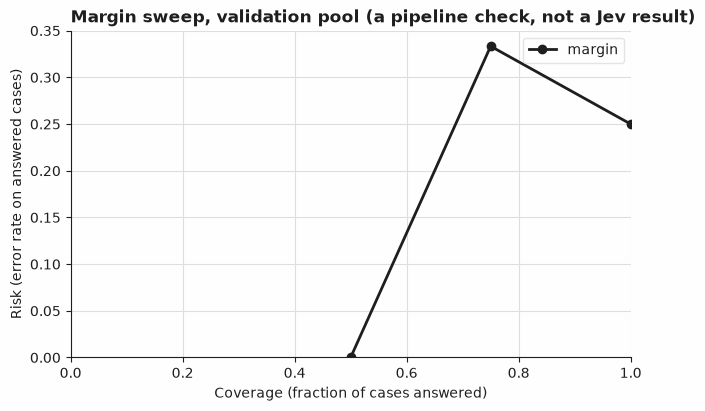

In [12]:
conf_curve = selective_curve(conf_correct, conf_pool)
print("confidence sweep over the validation pool, each distinct confidence as a gate:")
for t, cov, acc, risk in zip(
    conf_curve.thresholds, conf_curve.coverage, conf_curve.accuracy, conf_curve.risk, strict=True
):
    print(
        f"  gate {t:.4f}: coverage {cov:.4f}, accuracy {acc:.4f}, risk {risk:.4f}{selection}{check}"
    )

margin_curve = selective_curve(pool_correct, pool_margin)
print("\nmargin sweep over the validation pool, each distinct margin as a gate:")
for t, cov, acc, risk in zip(
    margin_curve.thresholds,
    margin_curve.coverage,
    margin_curve.accuracy,
    margin_curve.risk,
    strict=True,
):
    print(
        f"  gate {t:.4f}: coverage {cov:.4f}, accuracy {acc:.4f}, risk {risk:.4f}{selection}{check}"
    )

plot_risk_coverage(margin_curve, label="margin", title=f"Margin sweep, validation pool{check}")

## What was and was not measured

What this run can say about Jev depends on its mode, which the cell below states from `backend.mode`: a synthetic or scripted run is a pipeline check only, on the fixture sample it ran against; a recorded or live run states the model the API returned and when, for exactly the examples it covers. Nothing here says anything about Jev's quality, speed or cost unless that cell reports a recorded or live run. Two `N`s are stated below, because two different things are reported above: the number of (task, skill) requests the per-question agreement covers, and the number of tasks the composed, task-level decision covers. The three `demo` tasks shown earlier are excluded from both.

In [13]:
if offline:
    print(f"Provenance: {backend.mode}. Not measured live: a pipeline check, not a Jev result.")
    print(
        f"N: {len(val_examples)} validation and {len(test_examples)} test "
        f"(task, skill) requests{check}"
    )
    print(f"N: {len(val_selections)} validation and {len(test_selections)} test tasks{check}")
else:
    dates = ", ".join(getattr(backend, "recorded_dates", ()) or ()) or "this run"
    print(f"Provenance: {backend.mode}, model {backend.model}")
    print(f"Captured: {dates}")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test (task, skill) requests")
    print(f"N: {len(val_selections)} validation and {len(test_selections)} test tasks")

Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 15 validation and 15 test (task, skill) requests (a pipeline check, not a Jev result)
N: 5 validation and 5 test tasks (a pipeline check, not a Jev result)


## Next steps

- Change one sentence in `helpers.SUITABLE` (or any other rubric level) and run `pytest recipes/28-skill-selection` or this notebook: the stored keys no longer match the question, so replay misses instead of guessing. `python build_fixtures.py` writes new keys but rewrites the committed fixtures; `git checkout recipes/28-skill-selection` restores them.
- Raise `helpers.MARGIN_MIN_COVERAGE` from `0.5` to `0.75` and rerun the `python-rule` and evaluation cells: the frozen margin threshold drops from about `0.78` to about `0.023`, low enough to admit `v04`'s and `t04`'s tied candidates. Both ambiguous tasks then get selected automatically instead of sent to review -- the clarification rate falls on both splits, and `test`'s top-1 accuracy among selected tasks moves too, because a task this recipe built to be genuinely ambiguous is no longer treated that way.
- Add a task to `build_fixtures.py` whose two closest candidates score even closer than `v04`'s or `t04`'s, run `python build_fixtures.py`, and see whether the margin threshold chosen on `validation` moves.
- Neighbouring recipes: [`11-clarification-selection`](../11-clarification-selection/) (the same ask-or-proceed shape, over a fixed catalog of follow-up questions instead of a skill catalog), [`17-passage-reranking`](../17-passage-reranking/) (the same one-`Score`-per-candidate pattern this recipe retrieves and ranks with), and [`29-tool-outcome-verification`](../29-tool-outcome-verification/), another agent-orchestration recipe that composes more than one judgment into a single decision.